# NASA FIRMS Hotspot Data Cleaning

## Project
Spatial-Temporal Clustering & Fire Severity Prediction
in Peatland Ecosystems of Kalimantan

## Objective
Perform data profiling, quality checking, cleaning, and
preparation of NASA FIRMS hotspot data for spatial analysis.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd

In [2]:
file_path = "../../data/raw/firms/fire_nrt_SV-C2_852079.csv"

df = pd.read_csv(file_path)

df.head()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight
0,-2.60134,114.62048,336.64,0.39,0.37,2026-09-01,603,SNPP,SNPP,l,2.0NRT,308.36,3.49,D
1,-2.70285,115.20812,349.14,0.41,0.37,2026-09-01,603,SNPP,SNPP,n,2.0NRT,314.52,6.30,D
2,-3.99778,116.15096,341.04,0.43,0.38,2026-09-01,603,SNPP,SNPP,n,2.0NRT,306.44,17.01,D
3,-4.16794,114.64697,338.07,0.39,0.36,2026-09-01,603,SNPP,SNPP,n,2.0NRT,306.18,6.17,D
4,-4.15681,114.65244,340.96,0.39,0.36,2026-09-01,603,SNPP,SNPP,n,2.0NRT,306.94,2.82,D


In [3]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

df.columns.tolist()

Jumlah baris: 210915
Jumlah kolom: 14


['latitude',
 'longitude',
 'brightness',
 'scan',
 'track',
 'acq_date',
 'acq_time',
 'satellite',
 'instrument',
 'confidence',
 'version',
 'bright_t31',
 'frp',
 'daynight']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 210915 entries, 0 to 210914
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   latitude    210915 non-null  float64
 1   longitude   210915 non-null  float64
 2   brightness  210915 non-null  float64
 3   scan        210915 non-null  float64
 4   track       210915 non-null  float64
 5   acq_date    210915 non-null  str    
 6   acq_time    210915 non-null  int64  
 7   satellite   210915 non-null  str    
 8   instrument  210915 non-null  str    
 9   confidence  210915 non-null  str    
 10  version     210915 non-null  str    
 11  bright_t31  210915 non-null  float64
 12  frp         210915 non-null  float64
 13  daynight    210915 non-null  str    
dtypes: float64(7), int64(1), str(6)
memory usage: 27.8 MB


In [5]:
df.isnull().sum()

latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,latitude,longitude,brightness,scan,track,acq_time,bright_t31,frp
count,210915.000000,210915.000000,210915.000000,210915.000000,210915.000000,210915.000000,210915.000000,210915.000000
mean,-2.195765,113.356787,326.101724,0.456247,0.464369,1309.406733,293.011631,7.229595
std,1.185890,1.916357,18.264318,0.080695,0.110661,583.305168,8.297589,13.594369
min,-4.175940,108.924010,208.000000,0.320000,0.360000,449.000000,239.500000,0.100000
25%,-2.945170,111.980240,308.610000,0.400000,0.370000,622.000000,290.030000,1.780000
50%,-2.533000,113.534580,328.150000,0.430000,0.420000,1739.000000,293.210000,3.610000
75%,-1.855355,114.460935,340.050000,0.500000,0.540000,1809.000000,297.400000,7.610000
max,6.975740,118.964080,367.000000,0.800000,0.780000,1913.000000,366.960000,843.010000


In [8]:
# Convert acq_date temporarily for validation
dates = pd.to_datetime(df["acq_date"], errors="coerce")

print("Tanggal paling awal:", dates.min())
print("Tanggal paling akhir:", dates.max())

print("\nJumlah tanggal invalid:", dates.isna().sum())

print("\nJumlah data per tanggal:")
print(dates.value_counts().sort_index())

Tanggal paling awal: 2026-09-01 00:00:00
Tanggal paling akhir: 2026-10-31 00:00:00

Jumlah tanggal invalid: 0

Jumlah data per tanggal:
acq_date
2026-09-01    7822
2026-09-02    4696
2026-09-03    5004
2026-09-04    3726
2026-09-05    4075
              ... 
2026-10-27     695
2026-10-28     226
2026-10-29     839
2026-10-30     832
2026-10-31     191
Name: count, Length: 61, dtype: int64


In [9]:
categorical_columns = [
    "satellite",
    "instrument",
    "confidence",
    "version",
    "daynight"
]

for column in categorical_columns:
    print(f"\n===== {column.upper()} =====")
    print(df[column].value_counts(dropna=False))


===== SATELLITE =====
satellite
SNPP    210915
Name: count, dtype: int64

===== INSTRUMENT =====
instrument
SNPP    210915
Name: count, dtype: int64

===== CONFIDENCE =====
confidence
n    196569
l      7760
h      6586
Name: count, dtype: int64

===== VERSION =====
version
2.0NRT    210915
Name: count, dtype: int64

===== DAYNIGHT =====
daynight
N    126659
D     84256
Name: count, dtype: int64


In [10]:
print("Latitude range:")
print("Min:", df["latitude"].min())
print("Max:", df["latitude"].max())

print("\nLongitude range:")
print("Min:", df["longitude"].min())
print("Max:", df["longitude"].max())

# Valid global coordinate check
invalid_coordinates = df[
    (df["latitude"] < -90) |
    (df["latitude"] > 90) |
    (df["longitude"] < -180) |
    (df["longitude"] > 180)
]

print("\nJumlah koordinat invalid:", len(invalid_coordinates))

Latitude range:
Min: -4.17594
Max: 6.97574

Longitude range:
Min: 108.92401
Max: 118.96408

Jumlah koordinat invalid: 0


In [11]:
duplicate_count = df.duplicated().sum()

print("Jumlah duplicate records:", duplicate_count)
print("Persentase duplikat:", round(duplicate_count / len(df) * 100, 4), "%")

Jumlah duplicate records: 0
Persentase duplikat: 0.0 %


In [12]:
print("FRP Statistics:")
print(df["frp"].describe(percentiles=[0.90, 0.95, 0.99, 0.999]))

print("\n10 nilai FRP tertinggi:")
df.nlargest(10, "frp")[
    ["latitude", "longitude", "acq_date", "acq_time", "brightness", "frp"]
]

FRP Statistics:
count    210915.000000
mean          7.229595
std          13.594369
min           0.100000
90%          15.310000
95%          24.200000
99%          57.940000
99.9%       158.690000
max         843.010000
Name: frp, dtype: float64

10 nilai FRP tertinggi:


,latitude,longitude,acq_date,acq_time,brightness,frp
157312,-2.80402,110.67850,2026-10-11,1758,355.25,843.01
157324,-2.80019,110.67910,2026-10-11,1758,367.00,843.01
69552,-3.13604,113.85005,2026-09-19,525,208.00,824.73
206928,-1.88039,110.18809,2026-10-24,612,367.00,529.28
65388,-2.07270,115.88849,2026-09-18,546,367.00,501.01
64768,-3.10827,113.86768,2026-09-18,546,208.00,470.35
21477,-1.84260,111.39249,2026-09-05,629,338.99,402.28
4472,1.03113,109.52294,2026-09-01,605,367.00,389.25
162616,-2.81142,110.66833,2026-10-14,557,367.00,384.09
64754,-3.12519,113.91563,2026-09-18,546,367.00,383.46


## 2. Data Cleaning

### 2.1 Date Conversion and Filtering

The dataset contains hotspot records from September to October 2026.
Since the research scope is limited to September 2026, the data will be
converted into datetime format and filtered to the research period.

In [13]:
# Create a working copy
df_clean = df.copy()

# Convert acquisition date to datetime
df_clean["acq_date"] = pd.to_datetime(
    df_clean["acq_date"],
    errors="coerce"
)

# Define research period
start_date = "2026-09-01"
end_date = "2026-09-30"

# Filter data for September 2026
df_clean = df_clean[
    (df_clean["acq_date"] >= start_date) &
    (df_clean["acq_date"] <= end_date)
].copy()

print("Periode data:", df_clean["acq_date"].min(), "-", df_clean["acq_date"].max())
print("Jumlah data setelah filtering:", len(df_clean))

Periode data: 2026-09-01 00:00:00 - 2026-09-30 00:00:00
Jumlah data setelah filtering: 115739


In [14]:
print("===== CLEANED DATA =====")

print("Total records:", len(df_clean))
print("Total columns:", len(df_clean.columns))

print("\nDate range:")
print(df_clean["acq_date"].min(), "to", df_clean["acq_date"].max())

print("\nHotspot per tanggal:")
print(df_clean["acq_date"].dt.date.value_counts().sort_index())

===== CLEANED DATA =====
Total records: 115739
Total columns: 14

Date range:
2026-09-01 00:00:00 to 2026-09-30 00:00:00

Hotspot per tanggal:
acq_date
2026-09-01    7822
2026-09-02    4696
2026-09-03    5004
2026-09-04    3726
2026-09-05    4075
2026-09-06    3069
2026-09-07    1386
2026-09-08    2352
2026-09-09    2064
2026-09-10    2252
2026-09-11    6579
2026-09-12    2467
2026-09-13    4451
2026-09-14    8097
2026-09-15    3583
2026-09-16    1063
2026-09-17    1768
2026-09-18    4665
2026-09-19    8965
2026-09-20    8132
2026-09-21    4438
2026-09-22    5771
2026-09-23    4102
2026-09-24    4207
2026-09-25    2543
2026-09-26    1928
2026-09-27    1264
2026-09-28    1791
2026-09-29    1838
2026-09-30    1641
Name: count, dtype: int64


In [15]:
# ==========================================
# DATA QUALITY CHECK
# ==========================================

print("===== DATA QUALITY CHECK =====")

# 1. Missing values
print("\n--- Missing Values ---")
print(df_clean.isnull().sum())

# 2. Duplicate records
print("\n--- Duplicate Records ---")
print("Jumlah duplikat:", df_clean.duplicated().sum())

# 3. Validasi koordinat
invalid_coordinates = df_clean[
    (df_clean["latitude"] < -90) |
    (df_clean["latitude"] > 90) |
    (df_clean["longitude"] < -180) |
    (df_clean["longitude"] > 180)
]

print("\n--- Coordinate Validation ---")
print("Jumlah koordinat invalid:", len(invalid_coordinates))

# 4. Validasi FRP
invalid_frp = df_clean[df_clean["frp"] < 0]

print("\n--- FRP Validation ---")
print("Jumlah FRP negatif:", len(invalid_frp))

# 5. Validasi periode
outside_period = df_clean[
    (df_clean["acq_date"] < "2026-09-01") |
    (df_clean["acq_date"] > "2026-09-30")
]

print("\n--- Date Validation ---")
print("Data di luar periode penelitian:", len(outside_period))

# 6. Confidence
print("\n--- Confidence Distribution ---")
print(df_clean["confidence"].value_counts())

# 7. Day / Night
print("\n--- Daynight Distribution ---")
print(df_clean["daynight"].value_counts())

# 8. Final summary
print("\n===== SUMMARY =====")
print("Total records:", len(df_clean))
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())
print("Invalid coordinates:", len(invalid_coordinates))
print("Negative FRP:", len(invalid_frp))
print("Outside research period:", len(outside_period))

===== DATA QUALITY CHECK =====

--- Missing Values ---
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
dtype: int64

--- Duplicate Records ---
Jumlah duplikat: 0

--- Coordinate Validation ---
Jumlah koordinat invalid: 0

--- FRP Validation ---
Jumlah FRP negatif: 0

--- Date Validation ---
Data di luar periode penelitian: 0

--- Confidence Distribution ---
confidence
n    106999
l      4876
h      3864
Name: count, dtype: int64

--- Daynight Distribution ---
daynight
N    65458
D    50281
Name: count, dtype: int64

===== SUMMARY =====
Total records: 115739
Missing values: 0
Duplicate records: 0
Invalid coordinates: 0
Negative FRP: 0
Outside research period: 0


In [16]:
# ==========================================
# LOAD PROVINCE BOUNDARIES
# ==========================================

boundary_path = "../../data/processed/boundaries/kalimantan_provinces.geojson"

gdf_provinces = gpd.read_file(boundary_path)

print("===== PROVINCE BOUNDARIES =====")

print("Jumlah polygon:", len(gdf_provinces))
print("CRS:", gdf_provinces.crs)

print("\nKolom boundary:")
print(gdf_provinces.columns.tolist())

print("\nNama provinsi:")
print(gdf_provinces.iloc[:, 0].tolist())

print("\nGeometry valid:")
print(gdf_provinces.geometry.is_valid.all())

===== PROVINCE BOUNDARIES =====
Jumlah polygon: 5
CRS: EPSG:4326

Kolom boundary:
['wadmpr', 'geometry']

Nama provinsi:
['Kalimantan Barat', 'Kalimantan Selatan', 'Kalimantan Tengah', 'Kalimantan Timur', 'Kalimantan Utara']

Geometry valid:
True


In [17]:
# ==========================================
# CONVERT HOTSPOTS TO GEODATAFRAME
# ==========================================

gdf_hotspots = gpd.GeoDataFrame(
    df_clean.copy(),
    geometry=gpd.points_from_xy(
        df_clean["longitude"],
        df_clean["latitude"]
    ),
    crs="EPSG:4326"
)

print("===== HOTSPOT GEODATAFRAME =====")

print("Jumlah data:", len(gdf_hotspots))
print("CRS:", gdf_hotspots.crs)

print("\nGeometry type:")
print(gdf_hotspots.geometry.geom_type.value_counts())

print("\nSample geometry:")
print(gdf_hotspots[["latitude", "longitude", "geometry"]].head())

===== HOTSPOT GEODATAFRAME =====
Jumlah data: 115739
CRS: EPSG:4326

Geometry type:
Point    115739
Name: count, dtype: int64

Sample geometry:
   latitude  longitude                    geometry
0  -2.60134  114.62048  POINT (114.62048 -2.60134)
1  -2.70285  115.20812  POINT (115.20812 -2.70285)
2  -3.99778  116.15096  POINT (116.15096 -3.99778)
3  -4.16794  114.64697  POINT (114.64697 -4.16794)
4  -4.15681  114.65244  POINT (114.65244 -4.15681)


In [18]:
# ==========================================
# SPATIAL JOIN: HOTSPOTS TO PROVINCES
# ==========================================

gdf_hotspots_province = gpd.sjoin(
    gdf_hotspots,
    gdf_provinces[["wadmpr", "geometry"]],
    how="left",
    predicate="within"
)

# Rename province column
gdf_hotspots_province = gdf_hotspots_province.rename(
    columns={"wadmpr": "province"}
)

print("===== SPATIAL JOIN RESULT =====")

print("Total hotspots:", len(gdf_hotspots_province))

print("\nHotspot per province:")
print(
    gdf_hotspots_province["province"]
    .value_counts(dropna=False)
)

print("\nHotspots without province:")
print(
    gdf_hotspots_province["province"]
    .isna()
    .sum()
)

===== SPATIAL JOIN RESULT =====
Total hotspots: 115739

Hotspot per province:
province
Kalimantan Tengah     67867
Kalimantan Barat      24853
Kalimantan Timur      11705
Kalimantan Selatan     9824
Kalimantan Utara        888
NaN                     602
Name: count, dtype: int64

Hotspots without province:
602


In [19]:
# ==========================================
# INVESTIGATION: UNMAPPED HOTSPOTS
# ==========================================

unmapped_hotspots = gdf_hotspots_province[
    gdf_hotspots_province["province"].isna()
].copy()

print("===== UNMAPPED HOTSPOTS =====")

print("Jumlah data:", len(unmapped_hotspots))

print("\nSample data:")
print(
    unmapped_hotspots[
        ["latitude", "longitude", "acq_date", "frp", "geometry"]
    ].head(10)
)

print("\nCoordinate range:")

print(
    "Latitude:",
    unmapped_hotspots["latitude"].min(),
    "-",
    unmapped_hotspots["latitude"].max()
)

print(
    "Longitude:",
    unmapped_hotspots["longitude"].min(),
    "-",
    unmapped_hotspots["longitude"].max()
)

===== UNMAPPED HOTSPOTS =====
Jumlah data: 602

Sample data:
      latitude  longitude   acq_date    frp                   geometry
4539   2.45595  117.95666 2026-09-01  20.08  POINT (117.95666 2.45595)
4543   2.46018  117.95605 2026-09-01   4.62  POINT (117.95605 2.46018)
4544   2.45960  117.95218 2026-09-01   4.62   POINT (117.95218 2.4596)
4551   2.46383  117.95156 2026-09-01   4.62  POINT (117.95156 2.46383)
4566   1.67042  112.00713 2026-09-01  10.69  POINT (112.00713 1.67042)
4596   2.03164  112.51567 2026-09-01   9.35  POINT (112.51567 2.03164)
4598   2.37327  114.51598 2026-09-01  17.01  POINT (114.51598 2.37327)
4599   2.37270  114.51215 2026-09-01  17.01   POINT (114.51215 2.3727)
4600   2.37558  114.50780 2026-09-01   4.87   POINT (114.5078 2.37558)
4601   2.37500  114.50398 2026-09-01   4.87    POINT (114.50398 2.375)

Coordinate range:
Latitude: -4.17594 - 6.97574
Longitude: 109.64114 - 118.65154


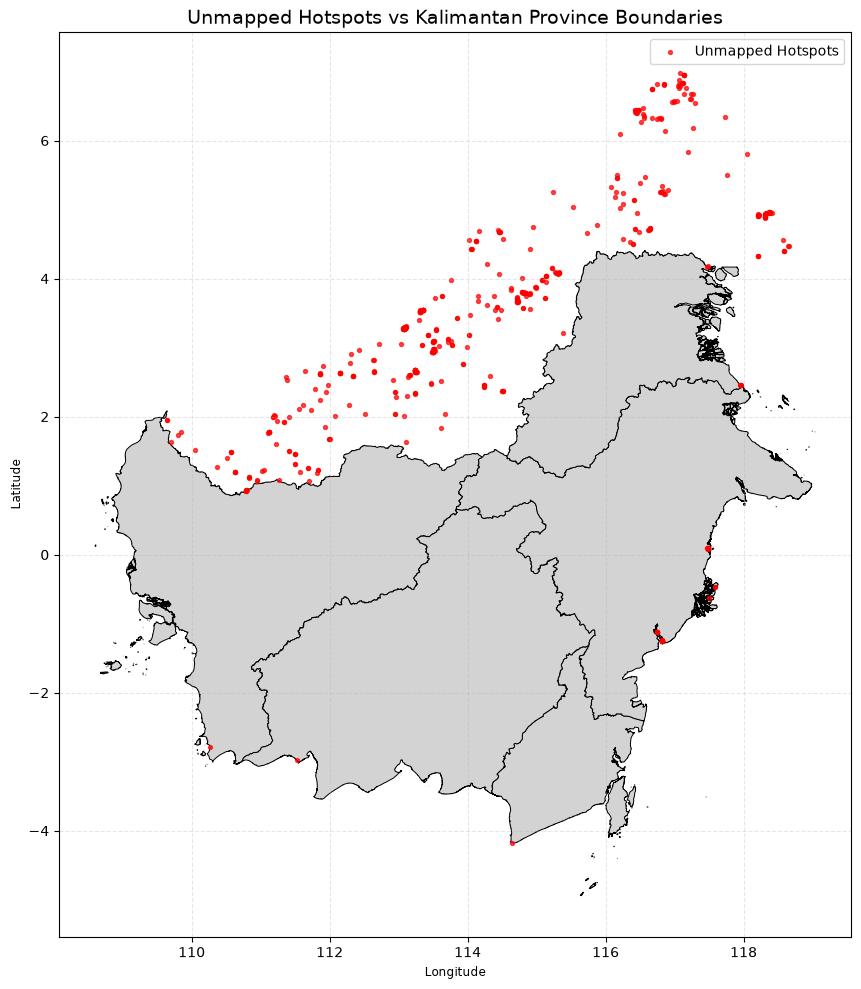

In [20]:
# ==========================================
# VISUALIZATION: UNMAPPED HOTSPOTS
# ==========================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

# Plot province boundaries
gdf_provinces.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.7
)

# Plot unmapped hotspots
unmapped_hotspots.plot(
    ax=ax,
    color="red",
    markersize=8,
    alpha=0.7,
    label="Unmapped Hotspots"
)

ax.set_title(
    "Unmapped Hotspots vs Kalimantan Province Boundaries",
    fontsize=14
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# FINAL DATASET SEPARATION
# ==========================================

# Hotspots inside the study area
gdf_hotspots_final = gdf_hotspots_province[
    gdf_hotspots_province["province"].notna()
].copy()

# Hotspots outside the mapped province boundaries
gdf_hotspots_outside = gdf_hotspots_province[
    gdf_hotspots_province["province"].isna()
].copy()

print("===== FINAL DATA SEPARATION =====")

print("Mapped hotspots:", len(gdf_hotspots_final))
print("Unmatched hotspots:", len(gdf_hotspots_outside))
print("Original total:", len(gdf_hotspots_province))

print(
    "Data consistency:",
    len(gdf_hotspots_final) + len(gdf_hotspots_outside)
    == len(gdf_hotspots_province)
)

===== FINAL DATA SEPARATION =====
Mapped hotspots: 115137
Outside study area: 602
Original total: 115739
Data consistency: True


In [22]:
# ==========================================
# VALIDATION: FINAL DATASET
# ==========================================

print("===== FINAL DATA VALIDATION =====")

# Province distribution
province_counts = gdf_hotspots_final["province"].value_counts()

print("\nHotspots per province:")
print(province_counts)

# Check total mapped records
print("\nTotal mapped hotspots:", len(gdf_hotspots_final))

# Check unique provinces
print("\nUnique provinces:")
print(gdf_hotspots_final["province"].unique())

# Check province count consistency
print("\nProvince count sum:", province_counts.sum())

# Check missing province
print(
    "Missing province:",
    gdf_hotspots_final["province"].isna().sum()
)

# Check duplicate records
print(
    "Duplicate records:",
    gdf_hotspots_final.duplicated().sum()
)

# Check date range
print(
    "Date range:",
    gdf_hotspots_final["acq_date"].min(),
    "to",
    gdf_hotspots_final["acq_date"].max()
)

===== FINAL DATA VALIDATION =====

Hotspots per province:
province
Kalimantan Tengah     67867
Kalimantan Barat      24853
Kalimantan Timur      11705
Kalimantan Selatan     9824
Kalimantan Utara        888
Name: count, dtype: int64

Total mapped hotspots: 115137

Unique provinces:
<ArrowStringArray>
[ 'Kalimantan Tengah', 'Kalimantan Selatan',   'Kalimantan Barat',
   'Kalimantan Timur',   'Kalimantan Utara']
Length: 5, dtype: str

Province count sum: 115137
Missing province: 0
Duplicate records: 0
Date range: 2026-09-01 00:00:00 to 2026-09-30 00:00:00


In [23]:
# ==========================================
# SAVE PROCESSED HOTSPOT DATA
# ==========================================

from pathlib import Path

# Create output directory
output_dir = Path("../../data/processed/firms")
output_dir.mkdir(parents=True, exist_ok=True)

# Remove spatial join metadata column
gdf_final_output = gdf_hotspots_final.drop(
    columns=["index_right"],
    errors="ignore"
).copy()

gdf_outside_output = gdf_hotspots_outside.drop(
    columns=["index_right"],
    errors="ignore"
).copy()

# 1. Save main dataset as CSV
csv_path = output_dir / "hotspots_kalimantan_september_2026.csv"

gdf_final_output.drop(columns="geometry").to_csv(
    csv_path,
    index=False
)

# 2. Save main dataset as GeoJSON
geojson_path = output_dir / "hotspots_kalimantan_september_2026.geojson"

gdf_final_output.to_file(
    geojson_path,
    driver="GeoJSON"
)

# 3. Save outside study area as CSV
outside_path = output_dir / "hotspots_outside_study_area_september_2026.csv"

gdf_outside_output.drop(columns="geometry").to_csv(
    outside_path,
    index=False
)

print("===== DATA SAVING RESULT =====")

print("Main CSV:", csv_path)
print("Main GeoJSON:", geojson_path)
print("Outside CSV:", outside_path)

print("\n===== RECORD COUNTS =====")

print("Main dataset:", len(gdf_final_output))
print("Outside dataset:", len(gdf_outside_output))

print("\nAll files saved successfully!")

===== DATA SAVING RESULT =====
Main CSV: ..\..\data\processed\firms\hotspots_kalimantan_september_2026.csv
Main GeoJSON: ..\..\data\processed\firms\hotspots_kalimantan_september_2026.geojson
Outside CSV: ..\..\data\processed\firms\hotspots_outside_study_area_september_2026.csv

===== RECORD COUNTS =====
Main dataset: 115137
Outside dataset: 602

All files saved successfully!


In [24]:
# ==========================================
# VERIFY SAVED FILES
# ==========================================

print("===== FILE VERIFICATION =====")

for file_path in [
    csv_path,
    geojson_path,
    outside_path
]:
    print(
        file_path.name,
        "| Exists:", file_path.exists(),
        "| Size:", round(file_path.stat().st_size / 1024, 2), "KB"
    )

===== FILE VERIFICATION =====
hotspots_kalimantan_september_2026.csv | Exists: True | Size: 11546.86 KB
hotspots_kalimantan_september_2026.geojson | Exists: True | Size: 48393.75 KB
hotspots_outside_study_area_september_2026.csv | Exists: True | Size: 49.99 KB


In [25]:
# ==========================================
# VERIFY PROCESSED DATA
# ==========================================

# Read saved files
df_saved = pd.read_csv(csv_path)
gdf_saved = gpd.read_file(geojson_path)
df_outside_saved = pd.read_csv(outside_path)

print("===== SAVED DATA VERIFICATION =====")

print("\nMain CSV:")
print("Records:", len(df_saved))
print("Columns:", len(df_saved.columns))

print("\nMain GeoJSON:")
print("Records:", len(gdf_saved))
print("CRS:", gdf_saved.crs)
print("Geometry:", gdf_saved.geometry.geom_type.value_counts())

print("\nOutside CSV:")
print("Records:", len(df_outside_saved))

# Final consistency checks
print("\n===== CONSISTENCY CHECK =====")

print("CSV and GeoJSON records match:",
      len(df_saved) == len(gdf_saved))

print("Total records match:",
      len(df_saved) + len(df_outside_saved) == 115739)

print("All provinces present:",
      set(df_saved["province"].unique()) == set(gdf_provinces["wadmpr"].unique()))

===== SAVED DATA VERIFICATION =====

Main CSV:
Records: 115137
Columns: 15

Main GeoJSON:
Records: 115137
CRS: EPSG:4326
Geometry: Point    115137
Name: count, dtype: int64

Outside CSV:
Records: 602

===== CONSISTENCY CHECK =====
CSV and GeoJSON records match: True
Total records match: True
All provinces present: True
